In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
# Chọn một tệp dữ liệu mẫu.
file = Path("car_data/20180713-home2mimos.csv")
# file = Path("car_data/20180713-mimos2home.csv")
lines = file.read_text(encoding="utf-8-sig").splitlines()

# Tìm dòng kết thúc metadata và lấy tên các kênh.
log_index = next(
    i for i, line in enumerate(lines)
    if line.startswith("Log :")
)
columns = ["Time"] + [
    line.split(" : ", 1)[1]
    for line in lines[:log_index]
    if line.startswith("Channel :")
]

# Đọc bảng dữ liệu, bỏ qua metadata.
df1 = pd.read_csv(file, skiprows=log_index + 1, names=columns)

# print("Số dòng, số cột:", df1.shape)
# df1.head()

# Kiểu dữ liệu và số giá trị có mặt trong từng cột
# df1.info()

In [2]:
print("\n".join(lines[:log_index + 1]))

%DataLog%
DataLogVersion : 1.0
Software : ECU Manager
SoftwareVersion : 1.1.14.0
DownloadDateTime : 20180713 08:37:23
Channel : BaseFuel
Type : Percentage
DisplayMaxMin : 2000,0
Channel : BaseIgnition
Type : AngleIgnSprt2K
DisplayMaxMin : 800,0
Channel : TargetAFR
Type : AFR
DisplayMaxMin : 2000,200
Channel : FuelCoolantTempCorrection
Type : Percentage1For1
DisplayMaxMin : 250,-100
Channel : FuelAirTempCorrection
Type : Percentage
DisplayMaxMin : 500,-500
Channel : ThrottlePosition
Type : Percentage
DisplayMaxMin : 1000,0
Channel : AirTemp
Type : Temperature
DisplayMaxMin : 4231,2331
Channel : CoolantTemp
Type : Temperature
DisplayMaxMin : 4231,2331
Channel : LambdaSensor1
Type : AFR
DisplayMaxMin : 2000,200
Channel : RPM
Type : EngineSpeed
DisplayMaxMin : 10000,0
Channel : Load
Type : Pressure
DisplayMaxMin : 1013,13
Channel : BatteryVoltage
Type : BatteryVoltage
DisplayMaxMin : 16000,8000
Channel : EngineRunningTime
Type : Time_s
DisplayMaxMin : 10000,0
Channel : DeltaLoad
Type : Per

In [3]:
df_work = df1.copy()

# Giữ thông tin nguồn và thứ tự bản ghi
df_work["trip_id"] = file.stem
df_work["source_row"] = range(len(df_work))

# Chuyển thời gian, giữ nguyên cột Time ban đầu
df_work["time_parsed"] = pd.to_timedelta(
    df_work["Time"], errors="coerce"
)

df_work["elapsed_s"] = (
    df_work["time_parsed"] - df_work["time_parsed"].iloc[0]
).dt.total_seconds()

df_work["dt_s"] = df_work["elapsed_s"].diff()

# Đánh dấu để kiểm tra, chưa xóa bản ghi
df_work["duplicate_time"] = df_work["Time"].duplicated(
    keep=False
)
df_work["time_backwards"] = df_work["dt_s"].lt(0)

df_work[["Time", "elapsed_s", "RPM"]].head(10)

,Time,elapsed_s,RPM
0,07:54:58.000,0.000,1164.0
1,07:54:58.031,0.031,1155.0
2,07:54:58.047,0.047,NaN
3,07:54:58.062,0.062,1168.0
4,07:54:58.078,0.078,NaN
5,07:54:58.109,0.109,NaN
6,07:54:58.140,0.140,1168.0
7,07:54:58.156,0.156,1169.0
8,07:54:58.250,0.250,1174.0
9,07:54:58.265,0.265,1180.0


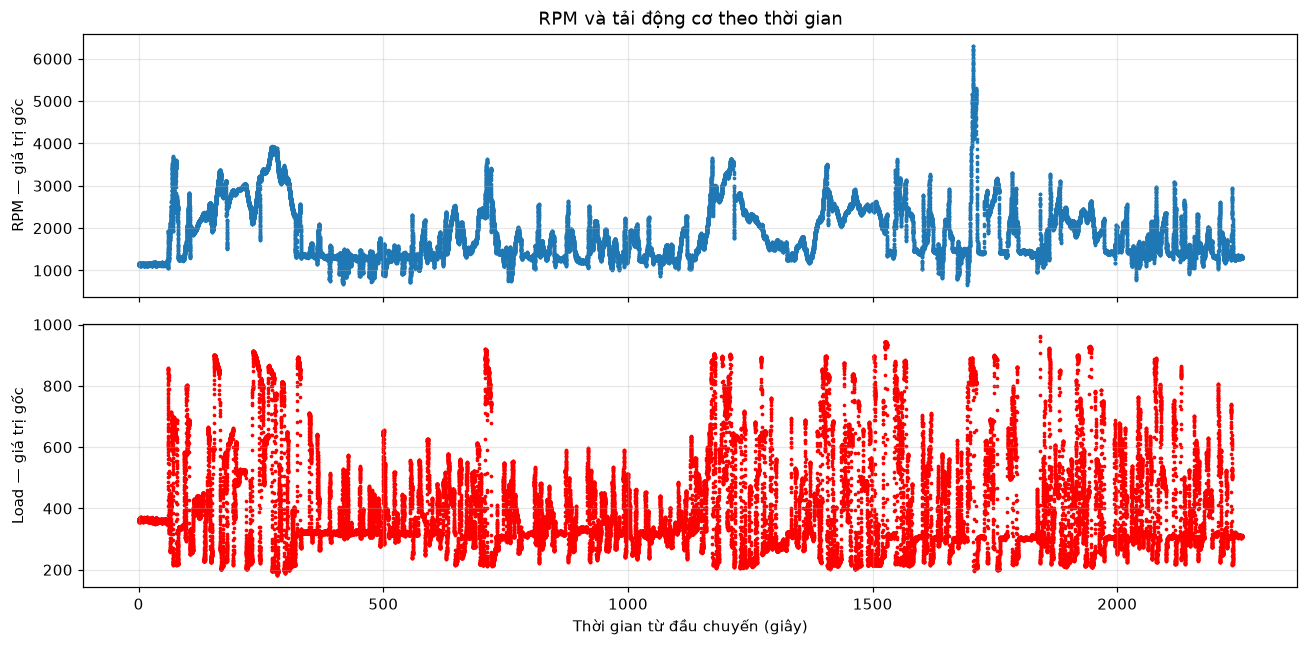

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

axes[0].scatter(df_work["elapsed_s"], df_work["RPM"], s=2)
axes[0].set_ylabel("RPM — giá trị gốc")
axes[0].set_title("RPM và tải động cơ theo thời gian")

axes[1].scatter(df_work["elapsed_s"], df_work["Load"], color='red', s=2)
axes[1].set_ylabel("Load — giá trị gốc")
axes[1].set_xlabel("Thời gian từ đầu chuyến (giây)")

for ax in axes:
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

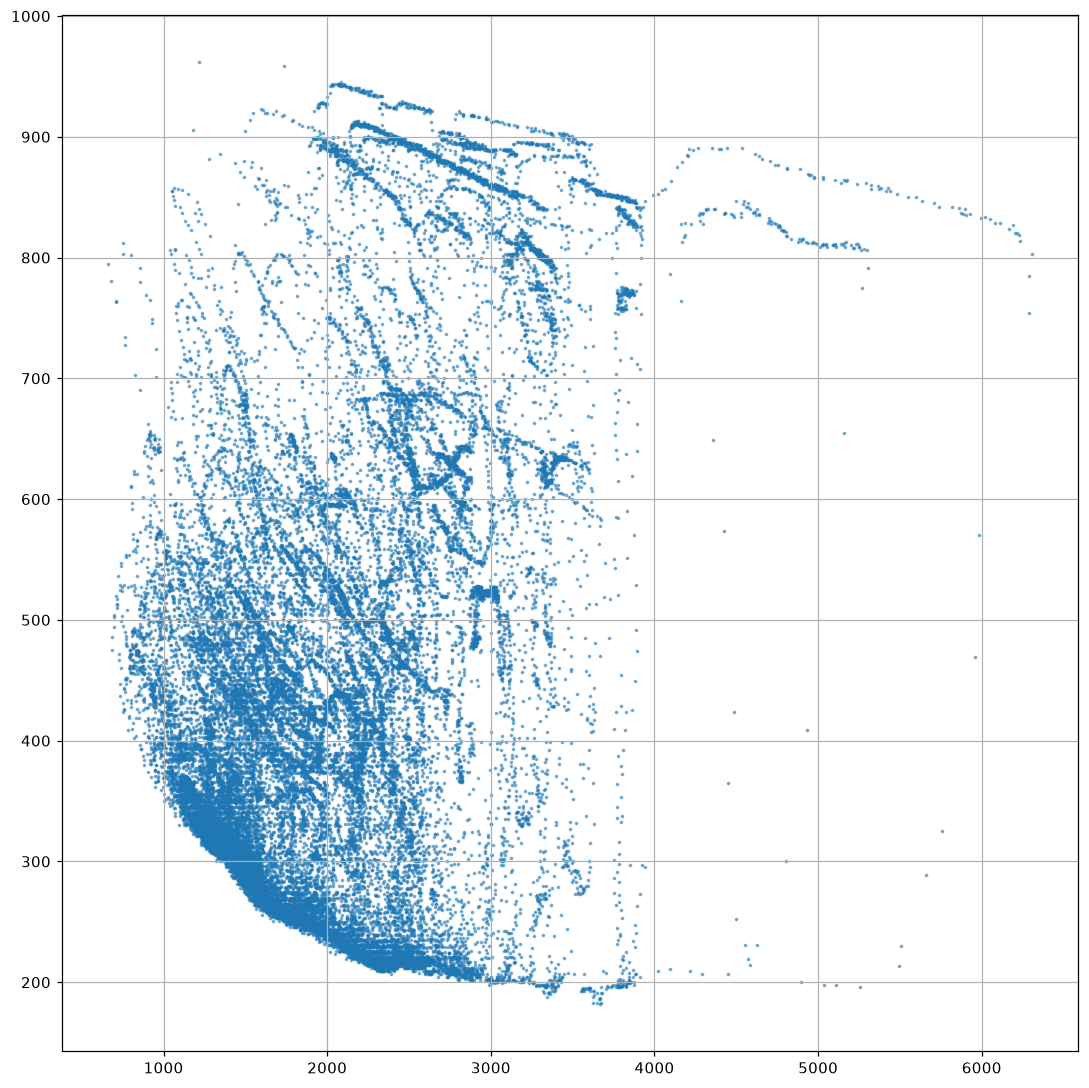

In [5]:
plt.figure(figsize=(10, 10))

plt.scatter(
    df_work["RPM"], df_work["Load"],
    s=2, alpha=0.5, label="RPM - Load"
)
plt.grid()
plt.tight_layout()
plt.show()

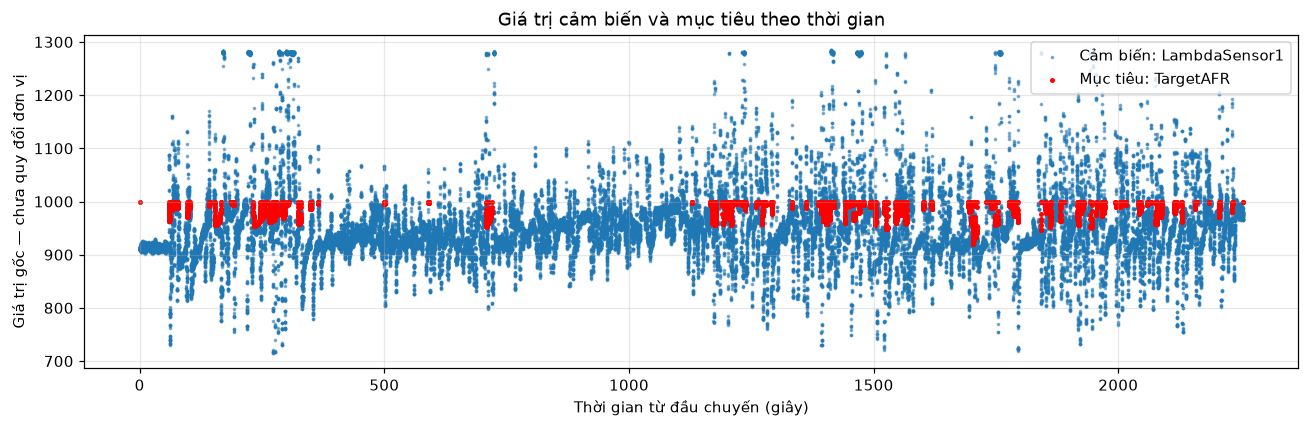

In [6]:
plt.figure(figsize=(12, 4))

plt.scatter(
    df_work["elapsed_s"], df_work["LambdaSensor1"],
    s=2, alpha=0.5, label="Cảm biến: LambdaSensor1"
)
plt.scatter(
    df_work["elapsed_s"], df_work["TargetAFR"],
    s=5, color="red", label="Mục tiêu: TargetAFR"
)

plt.xlabel("Thời gian từ đầu chuyến (giây)")
plt.ylabel("Giá trị gốc — chưa quy đổi đơn vị")
plt.title("Giá trị cảm biến và mục tiêu theo thời gian")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
channels = [
    "RPM", "Load", "BaseFuel",
    "TargetAFR", "LambdaSensor1",
    "CoolantTemp", "ThrottlePosition"
]

records = []

for col in channels:
    observed_time = df_work.loc[
        df_work[col].notna(), "elapsed_s"
    ]
    gaps = observed_time.diff().dropna()

    records.append({
        "channel": col,
        "observed_count": len(observed_time),
        "missing_pct": df_work[col].isna().mean() * 100,
        "median_gap_s": gaps.median(),
        "p95_gap_s": gaps.quantile(0.95),
        "max_gap_s": gaps.max(),
    })

channel_report = pd.DataFrame(records)
channel_report.round(3)

,channel,observed_count,missing_pct,median_gap_s,p95_gap_s,max_gap_s
0,RPM,60088,12.194,0.031,0.078,1.593
1,Load,52932,22.651,0.032,0.094,1.593
2,BaseFuel,50200,26.644,0.032,0.094,6.046
3,TargetAFR,3836,94.395,0.047,0.484,408.218
4,LambdaSensor1,58487,14.534,0.031,0.078,1.593
5,CoolantTemp,19151,72.015,0.047,0.563,13.343
6,ThrottlePosition,27996,59.090,0.046,0.235,13.140


In [8]:
check_columns = [
    "RPM", "Load", "BaseFuel",
    "TargetAFR", "LambdaSensor1",
    "AirTemp", "CoolantTemp", "BatteryVoltage"
]

df_work[check_columns].describe(
    percentiles=[0.01, 0.5, 0.99]
).T.round(2)

,count,mean,std,min,1%,50%,99%,max
RPM,60088.0,1866.93,671.13,660.0,964.0,1606.0,3783.0,6308.0
Load,52932.0,410.58,166.61,182.0,212.0,339.0,896.0,962.0
BaseFuel,50200.0,418.51,104.33,282.0,291.0,357.0,668.0,782.0
TargetAFR,3836.0,978.93,16.50,920.0,933.0,981.0,1000.0,1000.0
LambdaSensor1,58487.0,952.50,69.55,715.0,808.0,943.0,1280.0,1285.0
AirTemp,20060.0,3258.73,71.21,3090.0,3093.0,3274.0,3354.0,3357.0
CoolantTemp,19151.0,3529.62,68.36,3396.0,3398.0,3550.0,3615.0,3619.0
BatteryVoltage,55468.0,12985.39,143.76,12058.0,12637.0,12997.0,13231.0,13309.0


In [9]:
afr_check = df1[
    ["TargetAFR", "LambdaSensor1", "AFRDifference"]
].dropna().copy()

afr_check["difference_calculated"] = (
    afr_check["TargetAFR"] - afr_check["LambdaSensor1"]
)

afr_check["matches"] = (
    afr_check["difference_calculated"]
    == afr_check["AFRDifference"]
)

afr_check["matches"].value_counts()

,count
matches,
True,3438


## 9. Từ nhật ký một chuyến đến bản đồ BaseFuel cơ bản

Mục tiêu: mô tả `BaseFuel` đã được ghi nhận theo vùng **RPM × Load**,
giữ nguyên toàn bộ số đo và đơn vị gốc. Đây là bản đồ thực hành của một chuyến,
chưa phải bản đồ nhiên liệu đã hiệu chỉnh để nạp vào ECU.

Quy trình: kiểm tra đầu vào → gộp mốc thời gian trùng → tái dựng có giới hạn
→ lấy mẫu mỗi 0,1 giây → chia vùng → thống kê và vẽ bản đồ.

**Giả thiết cần ghi nhớ:** ô trống có thể là kênh chưa cập nhật. Notebook thử giữ
giá trị ghi gần nhất, chỉ lấy từ quá khứ và giới hạn độ cũ theo từng kênh.
Cơ chế xuất log chưa được xác nhận. Bản đồ từ các dòng đủ dữ liệu gốc được giữ
làm đối chiếu. Không nội suy các ô bản đồ còn trống.

In [10]:
import numpy as np
from IPython.display import display

# Các lựa chọn thử nghiệm cho bài học, không phải ngưỡng do tác giả cung cấp.
SAMPLE_PERIOD_S = 0.1
SEGMENT_GAP_S = 2.0
MAX_AGE_S = {
    "RPM": 0.25,
    "Load": 0.25,
    "BaseFuel": 0.25,
    "LambdaSensor1": 0.25,
    "TargetAFR": 2.0,
    "CoolantTemp": 2.0,
    "ThrottlePosition": 0.25,
}
RPM_BIN_WIDTH = 250
LOAD_BIN_WIDTH = 50  # Load gốc, không quy đổi đơn vị.
MIN_GRID_SAMPLES = 30  # 30 mốc × 0,1 s ≈ 3 s thời lượng đại diện.
MIN_FUEL_UPDATES = 5
CORE = ["RPM", "Load", "BaseFuel"]
MAP_CHANNELS = list(MAX_AGE_S)
assert SAMPLE_PERIOD_S > 0 and SEGMENT_GAP_S > 0
assert RPM_BIN_WIDTH > 0 and LOAD_BIN_WIDTH > 0
assert MIN_GRID_SAMPLES >= 1 and MIN_FUEL_UPDATES >= 1
assert all(value >= 0 for value in MAX_AGE_S.values())

display(pd.Series(MAX_AGE_S, name="max_age_s").to_frame())

,max_age_s
RPM,0.25
Load,0.25
BaseFuel,0.25
LambdaSensor1,0.25
TargetAFR,2.00
CoolantTemp,2.00
ThrottlePosition,0.25


### 9.1. Kiểm tra đầu vào và bảo toàn dữ liệu gốc

`df1` được giữ nguyên. `df_raw` bổ sung mã chuyến và thứ tự bản ghi (đánh số từ 0).
Kiểm tra thời gian, số không hữu hạn, lỗi chuyển kiểu và các dòng trùng hoàn toàn.
Nếu thời gian lỗi/đi lùi hoặc số không hợp lệ xuất hiện, dừng để kiểm tra nguồn.

In [11]:
df_raw = df1.copy(deep=True)
df_raw["trip_id"] = file.stem
df_raw["source_row"] = np.arange(len(df_raw))
missing_channels = set(MAP_CHANNELS) - set(df1.columns)
assert not missing_channels, f"Thiếu các kênh: {sorted(missing_channels)}"
assert len(df_raw) > 0, "CSV không có bản ghi."

parsed_time = pd.to_timedelta(df_raw["Time"], errors="coerce")
assert parsed_time.notna().all(), "Có Time không đọc được; kiểm tra trước khi tiếp tục."
assert parsed_time.diff().dropna().ge(pd.Timedelta(0)).all(), (
    "Thời gian đi lùi hoặc qua nửa đêm; cần xử lý trước khi lập bản đồ."
)
elapsed = parsed_time - parsed_time.iloc[0]
numeric = df_raw[MAP_CHANNELS].apply(pd.to_numeric, errors="coerce")
conversion_errors = (df_raw[MAP_CHANNELS].notna() & numeric.isna()).sum()
nonfinite = (numeric.notna() & ~np.isfinite(numeric)).sum()
assert conversion_errors.sum() == 0, conversion_errors.to_dict()
assert nonfinite.sum() == 0, nonfinite.to_dict()

input_quality = pd.DataFrame({
    "raw_dtype": df1[MAP_CHANNELS].dtypes.astype(str),
    "observed_count": numeric.notna().sum(),
    "missing_pct": numeric.isna().mean() * 100,
    "unique_observed": numeric.nunique(),
    "conversion_errors": conversion_errors,
    "nonfinite_values": nonfinite,
})
time_audit = pd.Series({
    "raw_rows": len(df_raw),
    "unique_timestamps": parsed_time.nunique(),
    "extra_rows_at_duplicate_times": parsed_time.duplicated().sum(),
    "fully_duplicate_rows": df1.duplicated().sum(),
    "duration_s": elapsed.iloc[-1].total_seconds(),
    "largest_gap_s": elapsed.diff().dt.total_seconds().max(),
}, name="value")
display(input_quality.round(3), time_audit.to_frame())

,raw_dtype,observed_count,missing_pct,unique_observed,conversion_errors,nonfinite_values
RPM,float64,60088,12.194,2547,0,0
Load,float64,52932,22.651,762,0,0
BaseFuel,float64,50200,26.644,448,0,0
LambdaSensor1,float64,58487,14.534,545,0,0
TargetAFR,float64,3836,94.395,81,0,0
CoolantTemp,float64,19151,72.015,150,0,0
ThrottlePosition,float64,27996,59.090,456,0,0


,value
raw_rows,68433.000
unique_timestamps,68373.000
extra_rows_at_duplicate_times,60.000
fully_duplicate_rows,0.000
duration_s,2254.906
largest_gap_s,1.593


### 9.2. Các dòng có cùng thời gian

Quy ước trên bảng phân tích: lấy **giá trị không khuyết cuối cùng của mỗi kênh**
tại cùng một mốc, theo thứ tự bản ghi gốc. Bản ghi nguồn vẫn còn trong `df_raw`.
Nếu một kênh có nhiều giá trị khác nhau ở cùng mốc, ghi số trường hợp vào báo cáo.
Bảng sau gộp có thể ghép giá trị từ nhiều dòng cùng thời gian; không khẳng định
chúng là một phép đo đồng thời ở độ phân giải cao hơn log.

In [12]:
event_source = numeric.copy()
event_source["elapsed"] = elapsed
event_source["source_row"] = df_raw["source_row"]
by_time = event_source.groupby("elapsed", sort=True)
duplicate_conflicts = by_time[MAP_CHANNELS].nunique().gt(1).sum().rename(
    "timestamps_with_conflicting_values"
).to_frame()
events = by_time[MAP_CHANNELS].last()
event_sources = by_time["source_row"].agg(["min", "max", "count"])
events["segment_id"] = (
    events.index.to_series().diff().dt.total_seconds().gt(SEGMENT_GAP_S)
    .cumsum().to_numpy()
)
assert len(events) == parsed_time.nunique()
assert events.index.is_unique and events.index.is_monotonic_increasing
display(duplicate_conflicts, event_sources.query("count > 1").head(10))
print("Số đoạn ghi liên tục:", events["segment_id"].nunique())

,timestamps_with_conflicting_values
RPM,44
Load,29
BaseFuel,43
LambdaSensor1,45
TargetAFR,1
CoolantTemp,8
ThrottlePosition,20


,min,max,count
elapsed,,,
0 days 00:03:20.312000,7909,7910,2
0 days 00:05:12.594000,12248,12249,2
0 days 00:05:12.953000,12260,12261,2
0 days 00:05:13.125000,12266,12267,2
0 days 00:05:13.453000,12280,12281,2
0 days 00:08:42.297000,20305,20306,2
0 days 00:12:51.750000,27564,27565,2
0 days 00:12:52.062000,27574,27575,2
0 days 00:12:52.140000,27577,27578,2


Số đoạn ghi liên tục: 1


### 9.3. Xử lý khuyết và tạo lưới thời gian 0,1 giây

Tại mốc $t$, tìm lần ghi không khuyết gần nhất $t_k \leq t$ cho từng kênh:

$$x^*(t)=x(t_k)\quad\text{khi}\quad 0\leq t-t_k\leq A_x.$$

$A_x$ là `MAX_AGE_S` của kênh. Ngoài giới hạn này giữ `NaN`. Không lấy dữ liệu
từ tương lai, không truyền giá trị qua ranh giới đoạn ghi, không dùng trung bình
để điền khuyết. Cột `__age_s` lưu độ cũ; `__source_elapsed_s` lưu thời điểm nguồn;
`__carried` đánh dấu giá trị được mang từ mốc trước đến mốc lưới.

Lưới đều giúp vùng có nhiều bản ghi cập nhật không tự động được tính trọng số lớn
hơn vùng có cùng thời lượng nhưng ít bản ghi. Số mốc lưới không phải số phép đo độc lập.
Thay đổi các giả thiết ở phần cài đặt rồi chạy lại các cell phía dưới để so sánh.

In [13]:
step = pd.to_timedelta(SAMPLE_PERIOD_S, unit="s")
parts = []
for segment_id, segment in events.groupby("segment_id", sort=True):
    grid = pd.timedelta_range(
        start=segment.index.min().ceil(step),
        end=segment.index.max().floor(step), freq=step,
        name="elapsed",
    )
    if len(grid) == 0:
        continue
    union_index = segment.index.union(grid).sort_values()
    history = segment[MAP_CHANNELS].reindex(union_index).ffill()
    aligned_part = pd.DataFrame(index=grid)
    aligned_part["segment_id"] = segment_id
    grid_seconds = pd.Series(grid.total_seconds(), index=grid)
    for channel, max_age in MAX_AGE_S.items():
        recorded_at = pd.Series(
            segment.index.total_seconds(), index=segment.index
        ).where(segment[channel].notna())
        last_recorded = recorded_at.reindex(union_index).ffill().reindex(grid)
        age = grid_seconds - last_recorded
        fresh = age.ge(-1e-9) & age.le(max_age + 1e-9)
        aligned_part[channel] = history[channel].reindex(grid).where(fresh)
        aligned_part[channel + "__age_s"] = age
        aligned_part[channel + "__source_elapsed_s"] = last_recorded
        aligned_part[channel + "__carried"] = (
            aligned_part[channel].notna() & age.gt(1e-9)
        )
    parts.append(aligned_part)

assert parts, "Không có đoạn ghi đủ dài cho chu kỳ lấy mẫu đã chọn."
df_aligned = pd.concat(parts).sort_index()
df_aligned["elapsed_s"] = df_aligned.index.total_seconds()
df_aligned["trip_id"] = file.stem

alignment_report = pd.DataFrame({
    "raw_missing_pct": numeric.isna().mean() * 100,
    "grid_missing_pct": df_aligned[MAP_CHANNELS].isna().mean() * 100,
    "grid_carried_pct": pd.Series({
        c: df_aligned[c + "__carried"].mean() * 100 for c in MAP_CHANNELS
    }),
    "max_allowed_age_s": pd.Series(MAX_AGE_S),
})
display(alignment_report.round(3))
print("Tỷ lệ thiếu gốc và lưới dùng hai tập mốc thời gian khác nhau.")
display(df_aligned[["elapsed_s", "RPM", "RPM__age_s", "Load", "BaseFuel"]].head(12))

,raw_missing_pct,grid_missing_pct,grid_carried_pct,max_allowed_age_s
RPM,12.194,0.111,91.002,0.25
Load,22.651,0.701,91.361,0.25
BaseFuel,26.644,3.175,89.406,0.25
LambdaSensor1,14.534,0.111,91.135,0.25
TargetAFR,94.395,78.319,21.069,2.00
CoolantTemp,72.015,4.674,92.412,2.00
ThrottlePosition,59.090,27.410,68.594,0.25


Tỷ lệ thiếu gốc và lưới dùng hai tập mốc thời gian khác nhau.


,elapsed_s,RPM,RPM__age_s,Load,BaseFuel
elapsed,,,,,
0 days 00:00:00,0.0,1164.0,0.000,360.0,357.0
0 days 00:00:00.100000,0.1,1168.0,0.038,361.0,358.0
0 days 00:00:00.200000,0.2,1169.0,0.044,358.0,356.0
0 days 00:00:00.300000,0.3,1176.0,0.003,356.0,357.0
0 days 00:00:00.400000,0.4,1151.0,0.025,361.0,356.0
0 days 00:00:00.500000,0.5,1158.0,0.000,361.0,357.0
0 days 00:00:00.600000,0.6,1161.0,0.053,361.0,357.0
0 days 00:00:00.700000,0.7,1161.0,0.013,359.0,356.0
0 days 00:00:00.800000,0.8,1133.0,0.003,362.0,354.0


### 9.4. Kiểm chứng bảng đồng bộ và chọn các mốc dùng lập bản đồ

Kiểm tra giá trị truy về đúng nguồn và không vượt độ cũ cho phép. Chỉ dùng các mốc
có đủ RPM, Load, BaseFuel hữu hạn, RPM > 0, Load ≥ 0 và BaseFuel > 0.
Đây là bộ lọc tối thiểu cho bản đồ mô tả. Chưa lọc động cơ nóng/vận hành ổn định,
chưa bù độ trễ cảm biến, chưa loại điểm cực trị bằng ngưỡng thống kê tùy tiện.

,value
grid_rows,22550.000
missing_core_rows,764.000
complete_but_outside_basic_range,0.000
map_rows,21786.000
retained_pct,96.612
represented_time_s,2178.600


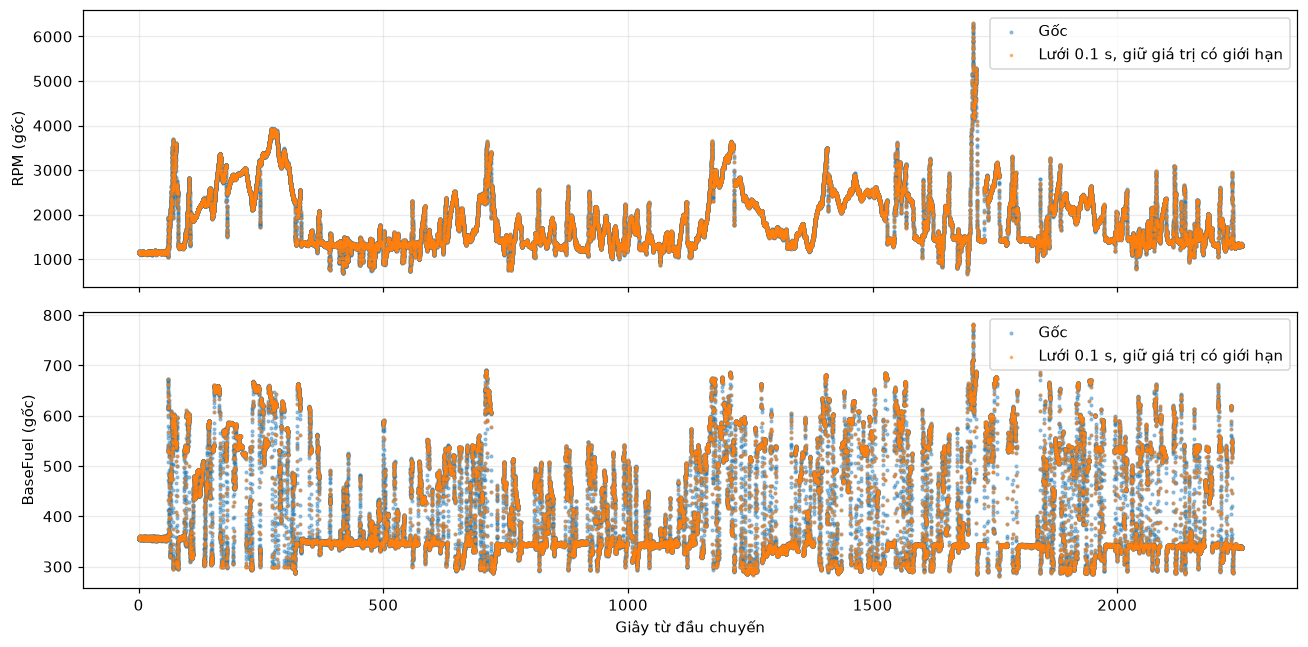

In [14]:
for channel, max_age in MAX_AGE_S.items():
    valid = df_aligned[channel].notna()
    ages = df_aligned.loc[valid, channel + "__age_s"]
    assert ages.ge(-1e-9).all() and ages.le(max_age + 1e-9).all()
    source_time = df_aligned.loc[valid, channel + "__source_elapsed_s"]
    # Tra lại thời điểm nguồn để bảo đảm không tạo ra số đo mới.
    lookup = pd.Series(events[channel].to_numpy(), index=events.index.total_seconds())
    expected = lookup.reindex(source_time.to_numpy()).to_numpy()
    np.testing.assert_allclose(
        df_aligned.loc[valid, channel].to_numpy(), expected, rtol=0, atol=0
    )
    source_segments = pd.Series(
        events["segment_id"].to_numpy(), index=events.index.total_seconds()
    ).reindex(source_time.to_numpy()).to_numpy()
    assert (source_segments == df_aligned.loc[valid, "segment_id"].to_numpy()).all()

complete = df_aligned[CORE].notna().all(axis=1)
basic_range = (
    df_aligned["RPM"].gt(0) & df_aligned["Load"].ge(0)
    & df_aligned["BaseFuel"].gt(0)
)
df_aligned["usable_for_map"] = complete & basic_range
map_points = df_aligned.loc[df_aligned["usable_for_map"]].copy()
assert not map_points.empty, "Không có mốc hợp lệ để lập bản đồ."

selection_report = pd.Series({
    "grid_rows": len(df_aligned),
    "missing_core_rows": (~complete).sum(),
    "complete_but_outside_basic_range": (complete & ~basic_range).sum(),
    "map_rows": len(map_points),
    "retained_pct": 100 * len(map_points) / len(df_aligned),
    "represented_time_s": len(map_points) * SAMPLE_PERIOD_S,
}, name="value")
display(selection_report.round(3).to_frame())

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for ax, channel in zip(axes, ["RPM", "BaseFuel"]):
    ax.scatter(elapsed.dt.total_seconds(), numeric[channel], s=3, alpha=0.4, label="Gốc")
    ax.scatter(df_aligned["elapsed_s"], df_aligned[channel], s=2, alpha=0.5,
               label=f"Lưới {SAMPLE_PERIOD_S:g} s, giữ giá trị có giới hạn")
    ax.set_ylabel(channel + " (gốc)")
    ax.grid(alpha=0.25)
    ax.legend()
axes[-1].set_xlabel("Giây từ đầu chuyến")
fig.tight_layout()
plt.show()

### 9.5. Chia vùng RPM × Load và tính bản đồ

Các khoảng có dạng `[cận dưới, cận trên)`: RPM rộng 250 và Load rộng 50 theo số đo
gốc. Trục phủ toàn bộ các mốc dùng lập bản đồ. Với ô $B_{ij}$:

$$F_{ij}=\operatorname{median}\{\mathrm{BaseFuel}(t):t\in B_{ij}\}.$$

Tính thêm số mốc, thời lượng đại diện, số thời điểm nguồn BaseFuel khác nhau và
IQR = phân vị 75% − phân vị 25%. Số thời điểm nguồn khác nhau không bảo đảm độc lập.
Chỉ hiển thị giá trị trên bản đồ chính khi ô có ít nhất 30 mốc lưới và 5 thời điểm
nguồn BaseFuel. Đây là quy tắc lọc thưa để thực hành, chưa phải kiểm định độ tin cậy.

In [15]:
rpm_edges = np.arange(
    np.floor(map_points["RPM"].min() / RPM_BIN_WIDTH) * RPM_BIN_WIDTH,
    (np.floor(map_points["RPM"].max() / RPM_BIN_WIDTH) + 2) * RPM_BIN_WIDTH,
    RPM_BIN_WIDTH,
)
load_edges = np.arange(
    np.floor(map_points["Load"].min() / LOAD_BIN_WIDTH) * LOAD_BIN_WIDTH,
    (np.floor(map_points["Load"].max() / LOAD_BIN_WIDTH) + 2) * LOAD_BIN_WIDTH,
    LOAD_BIN_WIDTH,
)
map_points["rpm_bin"] = pd.cut(map_points["RPM"], rpm_edges, right=False)
map_points["load_bin"] = pd.cut(map_points["Load"], load_edges, right=False)
assert map_points[["rpm_bin", "load_bin"]].notna().all().all()

cell_stats = map_points.groupby(["load_bin", "rpm_bin"], observed=True).agg(
    n_grid=("BaseFuel", "size"),
    n_fuel_updates=("BaseFuel__source_elapsed_s", "nunique"),
    basefuel_median=("BaseFuel", "median"),
    basefuel_q25=("BaseFuel", lambda x: x.quantile(0.25)),
    basefuel_q75=("BaseFuel", lambda x: x.quantile(0.75)),
    rpm_median=("RPM", "median"),
    load_median=("Load", "median"),
)
cell_stats["represented_time_s"] = cell_stats["n_grid"] * SAMPLE_PERIOD_S
cell_stats["basefuel_iqr"] = cell_stats["basefuel_q75"] - cell_stats["basefuel_q25"]
cell_stats["supported"] = (
    cell_stats["n_grid"].ge(MIN_GRID_SAMPLES)
    & cell_stats["n_fuel_updates"].ge(MIN_FUEL_UPDATES)
)
rpm_intervals = pd.IntervalIndex.from_breaks(rpm_edges, closed="left")
load_intervals = pd.IntervalIndex.from_breaks(load_edges, closed="left")

def map_matrix(column):
    return cell_stats[column].unstack("rpm_bin").reindex(
        index=load_intervals, columns=rpm_intervals
    )

coverage_map = map_matrix("n_grid").fillna(0).astype(int)
duration_map = coverage_map * SAMPLE_PERIOD_S
fuel_map_all = map_matrix("basefuel_median")
support_map = map_matrix("supported").eq(True)
fuel_map = fuel_map_all.where(support_map)
dispersion_map = map_matrix("basefuel_iqr").where(support_map)
assert coverage_map.to_numpy().sum() == len(map_points)
assert fuel_map.notna().equals(support_map)

print(f"Ô có quan sát: {(coverage_map > 0).to_numpy().sum()}/{coverage_map.size}")
print(f"Ô đạt quy tắc lọc thưa: {support_map.to_numpy().sum()}/{coverage_map.size}")
print("Ô trống vẫn là NaN; không tự tạo số liệu ở vùng chưa được ghi nhận.")
display(cell_stats.sort_values("n_grid", ascending=False).head(12).round(2))

Ô có quan sát: 220/408
Ô đạt quy tắc lọc thưa: 98/408
Ô trống vẫn là NaN; không tự tạo số liệu ở vùng chưa được ghi nhận.


n_grid  ...  supported
load_bin       rpm_bin                   ...           
[300.0, 350.0) [1250.0, 1500.0)    5972  ...       True
[250.0, 300.0) [1500.0, 1750.0)    1241  ...       True
[350.0, 400.0) [1000.0, 1250.0)     840  ...       True
[200.0, 250.0) [2250.0, 2500.0)     631  ...       True
[300.0, 350.0) [1000.0, 1250.0)     599  ...       True
[200.0, 250.0) [2000.0, 2250.0)     558  ...       True
[250.0, 300.0) [1750.0, 2000.0)     510  ...       True
               [1250.0, 1500.0)     427  ...       True
[350.0, 400.0) [1250.0, 1500.0)     356  ...       True
[400.0, 450.0) [1500.0, 1750.0)     344  ...       True
[350.0, 400.0) [1750.0, 2000.0)     294  ...       True
[300.0, 350.0) [1500.0, 1750.0)     282  ...       True

[12 rows x 10 columns]

### 9.6. Bản đồ độ phủ, BaseFuel và độ phân tán

Trục ngang là RPM, trục dọc là Load. Màu xám là không có dữ liệu hoặc chưa đạt
quy tắc lọc thưa (ở bản đồ BaseFuel/IQR). Các bản đồ sử dụng cận vùng thực,
không làm mượt hay nội suy. IQR lớn gợi ý cần xem lại độ rộng vùng hoặc trạng thái
vận hành bên trong vùng; IQR nhỏ chưa chứng minh giá trị nhiên liệu là tối ưu.

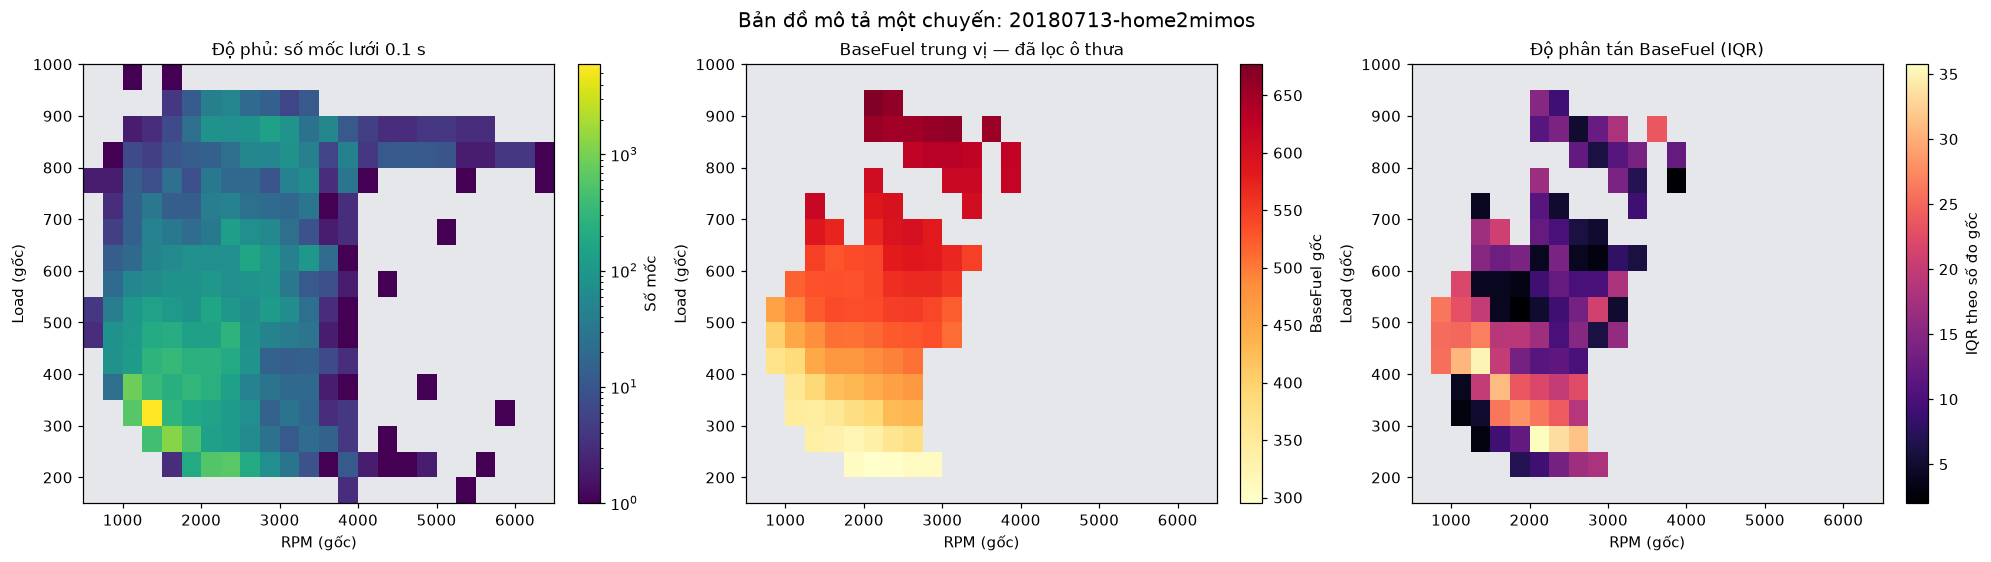

In [16]:
from matplotlib.colors import LogNorm

fig_maps, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)
layers = [
    (coverage_map.where(coverage_map > 0), f"Độ phủ: số mốc lưới {SAMPLE_PERIOD_S:g} s", "Số mốc", "viridis"),
    (fuel_map, "BaseFuel trung vị — đã lọc ô thưa", "BaseFuel gốc", "YlOrRd"),
    (dispersion_map, "Độ phân tán BaseFuel (IQR)", "IQR theo số đo gốc", "magma"),
]
for i, (ax, (matrix, title, label, palette)) in enumerate(zip(axes, layers)):
    cmap = plt.get_cmap(palette).copy()
    cmap.set_bad("#e5e7eb")
    kwargs = {}
    if i == 0:
        vmax = max(2, int(coverage_map.to_numpy().max()))
        kwargs["norm"] = LogNorm(vmin=1, vmax=vmax)
    image = ax.pcolormesh(
        rpm_edges, load_edges, np.ma.masked_invalid(matrix.to_numpy(dtype=float)),
        cmap=cmap, shading="flat", **kwargs,
    )
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("RPM (gốc)")
    ax.set_ylabel("Load (gốc)")
    fig_maps.colorbar(image, ax=ax, label=label)
fig_maps.suptitle(f"Bản đồ mô tả một chuyến: {file.stem}", fontsize=13)
plt.show()

### 9.7. Đối chiếu với các dòng đủ dữ liệu gốc

Tính trung vị trên các dòng gốc có đủ RPM, Load, BaseFuel (không điền khuyết),
dùng cùng các vùng. So sánh giúp thấy ảnh hưởng của việc tái dựng và lấy mẫu đều.
Hai cách có cách chọn/trọng số khác nhau nên chênh lệch không tự chứng minh một
cách đúng hơn. Bảng này chỉ gồm các vùng so sánh được trong miền bản đồ hiện tại.

In [17]:
raw_complete = numeric[CORE].dropna().copy()
raw_complete = raw_complete.loc[
    raw_complete["RPM"].gt(0) & raw_complete["Load"].ge(0)
    & raw_complete["BaseFuel"].gt(0)
]
raw_complete["rpm_bin"] = pd.cut(raw_complete["RPM"], rpm_edges, right=False)
raw_complete["load_bin"] = pd.cut(raw_complete["Load"], load_edges, right=False)
raw_baseline = raw_complete.groupby(["load_bin", "rpm_bin"], observed=True).agg(
    raw_complete_rows=("BaseFuel", "size"), raw_basefuel_median=("BaseFuel", "median")
)
comparison = cell_stats.join(raw_baseline, how="left")
comparison["aligned_minus_raw_median"] = (
    comparison["basefuel_median"] - comparison["raw_basefuel_median"]
)
print("Dòng gốc đủ ba kênh, qua bộ lọc tối thiểu:", len(raw_complete))
print("Dòng gốc nằm ngoài miền bản đồ:", raw_complete["rpm_bin"].isna().sum()
      + (raw_complete["rpm_bin"].notna() & raw_complete["load_bin"].isna()).sum())
display(comparison.loc[comparison["supported"], [
    "n_grid", "n_fuel_updates", "raw_complete_rows", "basefuel_median",
    "raw_basefuel_median", "aligned_minus_raw_median",
]].round(3).head(15))

Dòng gốc đủ ba kênh, qua bộ lọc tối thiểu: 41668
Dòng gốc nằm ngoài miền bản đồ: 0


n_grid  ...  aligned_minus_raw_median
load_bin       rpm_bin                   ...                          
[200.0, 250.0) [1750.0, 2000.0)     197  ...                       0.0
               [2000.0, 2250.0)     558  ...                      -1.0
               [2250.0, 2500.0)     631  ...                      -1.0
               [2500.0, 2750.0)     200  ...                      -3.0
               [2750.0, 3000.0)      73  ...                      -4.0
[250.0, 300.0) [1250.0, 1500.0)     427  ...                       0.0
               [1500.0, 1750.0)    1241  ...                       0.0
               [1750.0, 2000.0)     510  ...                       0.0
               [2000.0, 2250.0)     136  ...                      -3.0
               [2250.0, 2500.0)     115  ...                      -1.0
               [2500.0, 2750.0)      64  ...                       2.0
[300.0, 350.0) [1000.0, 1250.0)     599  ...                       0.0
               [1250.0, 1500.0)    5972  ...                      -1.0
               [1500.0, 1750.0)     282  ...                      -3.0
               [1750.0, 2000.0)     181  ...                      -1.5

[15 rows x 6 columns]

### 9.8. Sai lệch cảm biến và mục tiêu: kiểm tra bổ sung

Chỉ tính khi cả hai kênh còn trong giới hạn độ cũ. `target_minus_sensor_raw`
= TargetAFR − LambdaSensor1. Đây là chênh lệch theo số đo gốc, không phải “AFR thực”.
Thống kê này chưa bù độ trễ cảm biến hay chọn trạng thái vận hành ổn định,
do đó không dùng trực tiếp làm công thức hiệu chỉnh nhiên liệu.

In [18]:
afr_points = map_points.dropna(subset=["TargetAFR", "LambdaSensor1"]).copy()
afr_points["target_minus_sensor_raw"] = (
    afr_points["TargetAFR"] - afr_points["LambdaSensor1"]
)
afr_cell_stats = afr_points.groupby(["load_bin", "rpm_bin"], observed=True).agg(
    n_paired_grid=("target_minus_sensor_raw", "size"),
    median_target_minus_sensor_raw=("target_minus_sensor_raw", "median"),
)
print(f"Mốc đủ cặp cảm biến–mục tiêu: {len(afr_points):,}/{len(map_points):,}")
display(afr_cell_stats.sort_values("n_paired_grid", ascending=False).head(12).round(3))

Mốc đủ cặp cảm biến–mục tiêu: 4,688/21,786


n_paired_grid  median_target_minus_sensor_raw
load_bin       rpm_bin                                                        
[850.0, 900.0) [2750.0, 3000.0)            147                             7.0
[600.0, 650.0) [2500.0, 2750.0)            128                            10.0
[650.0, 700.0) [2250.0, 2500.0)            125                           -17.0
[250.0, 300.0) [1500.0, 1750.0)            106                           156.5
[200.0, 250.0) [2500.0, 2750.0)            103                           143.0
               [2250.0, 2500.0)            102                           127.0
[600.0, 650.0) [3250.0, 3500.0)             93                           -20.0
[200.0, 250.0) [2000.0, 2250.0)             90                           129.5
[850.0, 900.0) [3000.0, 3250.0)             83                            18.0
               [2000.0, 2250.0)             83                           -10.0
               [2500.0, 2750.0)             83                             9.0
[800.0, 850.0) [3000.0, 3250.0)             78                           -15.5

### 9.9. Lưu kết quả và đọc kết luận

Lưu bảng đã đồng bộ (kèm tuổi giá trị và cờ), báo cáo chất lượng, thống kê từng
vùng, các ma trận và hình bản đồ vào thư mục riêng theo tên chuyến.
Tham số được lưu cùng kết quả để chạy lại có thể truy vết. Giữ nguyên CSV nguồn.

Khi đọc kết quả, lần lượt xem: vùng được phủ → vùng đạt lọc thưa → BaseFuel trung vị
→ IQR → đối chiếu dữ liệu gốc. Muốn mở rộng bài tập, thay ngưỡng độ cũ hoặc độ rộng
vùng và xem bản đồ thay đổi thế nào, rồi kiểm chứng bằng các chuyến khác.

In [19]:
output_dir = Path("outputs") / file.stem
output_dir.mkdir(parents=True, exist_ok=True)
df_aligned.to_csv(output_dir / "aligned_data.csv", index_label="elapsed")
input_quality.to_csv(output_dir / "input_quality.csv", index_label="channel")
alignment_report.to_csv(output_dir / "alignment_report.csv", index_label="channel")
comparison.to_csv(output_dir / "cell_statistics.csv")
coverage_map.to_csv(output_dir / "coverage_map.csv", index_label="Load_bin")
fuel_map.to_csv(output_dir / "basefuel_map.csv", index_label="Load_bin")
dispersion_map.to_csv(output_dir / "basefuel_iqr_map.csv", index_label="Load_bin")
afr_cell_stats.to_csv(output_dir / "sensor_difference_by_cell.csv")
fig_maps.savefig(output_dir / "fuel_maps.png", dpi=160, bbox_inches="tight")

import json
settings = {
    "source_file": str(file), "source_rows": len(df_raw),
    "sample_period_s": SAMPLE_PERIOD_S, "segment_gap_s": SEGMENT_GAP_S,
    "max_age_s": MAX_AGE_S, "rpm_bin_width": RPM_BIN_WIDTH,
    "load_bin_width": LOAD_BIN_WIDTH, "min_grid_samples": MIN_GRID_SAMPLES,
    "min_fuel_updates": MIN_FUEL_UPDATES,
    "duplicate_time_rule": "last non-null per channel in original row order",
    "missing_value_assumption": "carry last observation, bounded age, unverified export semantics",
    "units": "unchanged raw values", "bin_intervals": "left closed, right open",
    "purpose": "descriptive one-trip BaseFuel map; no tuning correction",
}
(output_dir / "settings.json").write_text(
    json.dumps(settings, ensure_ascii=False, indent=2), encoding="utf-8"
)
pd.testing.assert_frame_equal(df1, df_raw[df1.columns])
print("Đã kiểm tra: bảng gốc không thay đổi; giá trị đồng bộ truy được về nguồn.")
print("Kết quả:", output_dir.resolve())
print("Bản đồ hiện tại mô tả BaseFuel của một chuyến; các ô chưa đủ dữ liệu được giữ trống.")

Đã kiểm tra: bảng gốc không thay đổi; giá trị đồng bộ truy được về nguồn.
Kết quả: D:\ECU_data\outputs\20180713-home2mimos
Bản đồ hiện tại mô tả BaseFuel của một chuyến; các ô chưa đủ dữ liệu được giữ trống.
